# Buổi 8: Bài toán phân cụm

In [1]:
import numpy as np
import random, os
from IPython import display

import matplotlib.pyplot as plt          # vẽ hình
from collections import Counter

import pandas as pd
from sklearn.datasets import make_blobs  # tạo tập điểm phân bố Gaussian
from sklearn.cluster import KMeans       # thuật toán phân cụm k-means

import warnings
warnings.filterwarnings("ignore")

# cố định random-state để phục hồi lại kết quả thí nghiệm
random_state = 42
random.seed(random_state)
os.environ['PYTHONHASHSEED'] = str(random_state)
np.random.seed(random_state)

## Bài 1. Tập hợp điểm hai chiều

### 1. Tạo và hiển thị dữ liệu

Tạo và hiển thị tập hợp điểm dữ liệu $X_1$ có chứa $N=400$ điểm hai chiều. Những tập hợp này bao gồm 4 nhóm bằng nhau, mỗi nhóm có hàm mật độ theo phân phối Gaussian với mean $m_0=\left(-2, -2\right)$ (cũ: $\left(0, 0\right)$), $m_1=\left(8, -2\right)$ (cũ: $\left(10, 0\right)$), $m_2=\left(-2, 7\right)$ (cũ: $\left(0, 9\right)$), và $m_3=\left(7, 6\right)$ (cũ: $\left(9, 8\right)$) và ma trận covariance tương ứng $S_0=0.8I$ (cũ: $I$), $S_1=1.2I$ (cũ: $1.5I$), $S_2=0.9I$ (cũ: $1.1I$), và $S_3=0.4I$ (cũ: $0.5I$).

In [2]:
# Sinh tập hợp điểm theo phân phối Gaussian
X1, y1 = make_blobs(n_samples    = 400,
                    centers      = [[-2,-2], [8,-2],[-2,7],[7,6]], # (cũ: [[0,0], [10,0],[0,9],[9,8]])
                    cluster_std  = [0.8, 1.2, 0.9, 0.4],          # (cũ: [1, 1.5, 1.1, 0.5])
                    random_state = random_state,
                   )

In [3]:
# lưu trữ trong pandas
df_points = pd.DataFrame(X1, columns=["x", "y"])
df_points["label"] = y1

# tính số lớp, tần số xuất hiện mỗi lớp
n_classes = len(np.unique(df_points["label"])) # tính số lớp dữ liệu
labels, cnts = np.unique(df_points["label"], return_counts=True)
n_cnts = dict(zip(labels, cnts))
print(f'+ labels={labels}\n+ cnts={cnts}\n+ n_cnts={n_cnts}')

# hiển thị dữ liệu
display.display(df_points)

+ labels=[0 1 2 3]
+ cnts=[100 100 100 100]
+ n_cnts={np.int64(0): np.int64(100), np.int64(1): np.int64(100), np.int64(2): np.int64(100), np.int64(3): np.int64(100)}


,x,y,label
0,-1.695353,6.626241,2
1,-2.405059,7.560565,2
2,6.790911,6.419604,3
3,7.011327,6.011902,3
4,6.604158,5.949685,3
...,...,...,...
395,8.896752,-1.267556,1
396,8.818344,-2.372320,1
397,-2.920795,-1.699442,0
398,-4.224480,6.282794,2


Center 0: [-2.0924514  -1.97278214]
Center 1: [ 8.15389847 -1.94781482]
Center 2: [-2.04053365  6.88635459]
Center 3: [6.96940717 6.03776615]


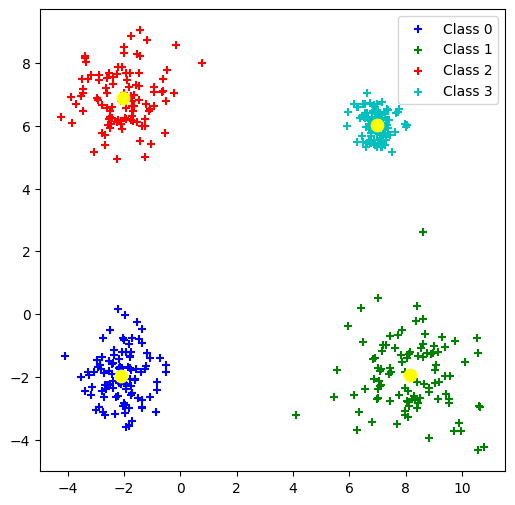

In [4]:
# màu của từng lớp
colors = {0:'b', 1:'g',2:'r',3:'c', 4:'m', 5:'y', 6:'k', 7:'w'}

# vẽ tập dữ liệu điểm
plt.figure(figsize=(6,6))     # độ lớn của khung vẽ
for i in range(n_classes):
    # tính toán điểm trung tâm từng lớp
    p_center = np.mean(X1[y1==i], axis = 0)
    print(f'Center {i}: {p_center}')
    # vẽ tập điểm
    plt.scatter(X1[y1==i, 0], X1[y1==i, 1], marker='+',
                c = colors[i], label = f"Class {i}")
    # vẽ tâm
    plt.scatter(p_center[0], p_center[1], marker='o',
                c='yellow', s = 80)
    pass # for
plt.legend()
plt.show()

### 2. Áp dụng thuật toán phân cụm

Thuật toán k-mean chia tập hợp $N$ mẫu $X_1$ thành $m$ cụm rời rạc $C$ (clusters), mỗi cụm được mô tả bằng giá trị trung bình của các mẫu trong cụm (thường được gọi là trung tâm cụm - centroid).

Thuật toán k-mean hướng tới chọn các centroids sao cho cực tiểu hóa độ đo khoảng cách (intertia) giữa các phần tử trong cụm (within-cluster). Độ đo hay dùng là tổng bình phương khoảng cách theo Euclide distance.

####  2.1. Số cụm m = 4 ngẫu nhiên

In [5]:
m = 4 # số cụm khởi tạo
kmeans = KMeans(n_clusters=m, random_state=random_state) # thuật toán kmean
kmeans.fit(X1); # huấn luyện tìm m cluster

cluster_centers = kmeans.cluster_centers_
cluster_inertia = kmeans.inertia_

# kiểm tra số mẫu phân lớp đúng
y_pred          = kmeans.labels_
correct_labels  = sum(y1 == y_pred) # tính độ chính xác

print(f'Centers:\n{cluster_centers}')
print(f'Inertia: {cluster_inertia}')
print(f'Correct Labels: {correct_labels} / {len(df_points)}')
print('Accuracy score: {0:0.2f}'. format(correct_labels/float(len(df_points))))

Centers:
[[ 8.14921    -1.99398747]
 [-2.04053365  6.88635459]
 [-2.0924514  -1.97278214]
 [ 6.98573044  6.00395933]]
Inertia: 573.1019378503071
Correct Labels: 100 / 400
Accuracy score: 0.25


**Lưu ý**:
+ Intertia là độ đo khoảng cách giữa các phần tử trong cụm. Giá trị càng nhỏ là càng tốt và tiến tới 0 là tốt nhất.
+ Chúng ta chỉ đạt được độ chính xác thấp 25% do đây là mô hình unsupervised (học không giám sát)

Predict: [1 1 3 3 3 3 1 0 2 2 1 2 3 2 2 2 1 0 2 0] ...
Center 0: [ 8.14921    -1.99398747]
Center 1: [-2.04053365  6.88635459]
Center 2: [-2.0924514  -1.97278214]
Center 3: [6.98573044 6.00395933]


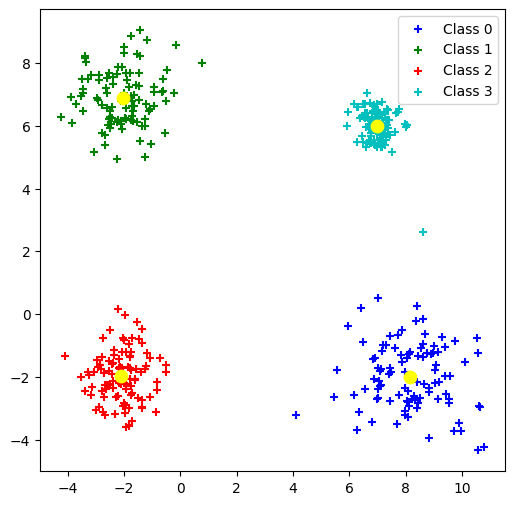

In [6]:
print(f'Predict: {y_pred[0:20]} ...')
# vẽ tập dữ liệu điểm dự đoán
plt.figure(figsize=(6,6))     # độ lớn của khung vẽ
for i in range(m):
    # Điểm trung tâm của lớp
    print(f'Center {i}: {cluster_centers[i]}')

    # vẽ tập điểm
    plt.scatter(X1[y_pred==i, 0], X1[y_pred==i, 1], marker='+',
                c = colors[i], label = f"Class {i}")
    # vẽ tâm
    plt.scatter(cluster_centers[i, 0], cluster_centers[i, 1], marker='o',
                c='yellow', s = 80)
    pass # for
plt.legend()
plt.show()

####  2.2. Số cụm m = 3 ngẫu nhiên

Centers:
[[ 7.56165282  2.04497566]
 [-2.04053365  6.88635459]
 [-2.0924514  -1.97278214]]
Inertia: 3838.8172216694725
Correct Labels: 0 / 400
Accuracy score: 0.00

Predict: [1 1 0 0 0 0 1 0 2 2 1 2 0 2 2 2 1 0 2 0] ...
Center 0: [7.56165282 2.04497566]
Center 1: [-2.04053365  6.88635459]
Center 2: [-2.0924514  -1.97278214]


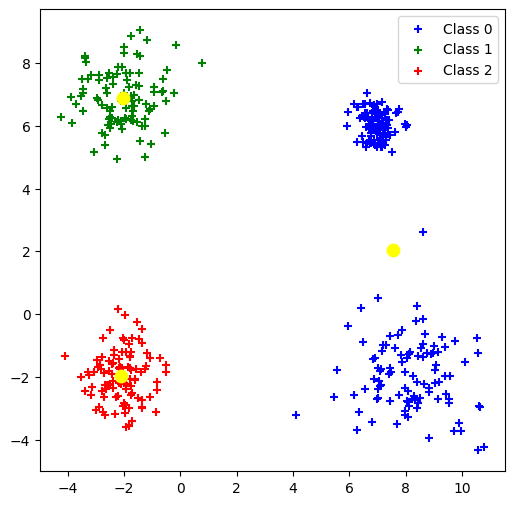

In [7]:
m = 3 # số cụm khởi tạo
kmeans = KMeans(n_clusters=m, random_state=random_state) # thuật toán kmean
kmeans.fit(X1); # huấn luyện tìm m cluster

cluster_centers = kmeans.cluster_centers_
cluster_inertia = kmeans.inertia_

# kiểm tra số mẫu phân lớp đúng
y_pred          = kmeans.labels_
correct_labels = sum(y1 == y_pred)

print(f'Centers:\n{cluster_centers}')
print(f'Inertia: {cluster_inertia}')
print(f'Correct Labels: {correct_labels} / {len(df_points)}')
print('Accuracy score: {0:0.2f}'. format(correct_labels/float(len(df_points))))

print()
print(f'Predict: {y_pred[0:20]} ...')
# vẽ tập dữ liệu điểm dự đoán
plt.figure(figsize=(6,6))     # độ lớn của khung vẽ
for i in range(m):
    # Điểm trung tâm của lớp
    print(f'Center {i}: {cluster_centers[i]}')

    # vẽ tập điểm
    plt.scatter(X1[y_pred==i, 0], X1[y_pred==i, 1], marker='+',
                c = colors[i], label = f"Class {i}")
    # vẽ tâm
    plt.scatter(cluster_centers[i, 0], cluster_centers[i, 1], marker='o',
                c='yellow', s = 80)
    pass # for
plt.legend()
plt.show()

#### 2.3. Số cụm m = 5 ngẫu nhiên

Centers:
[[ 7.19736901 -1.96143949]
 [-2.04053365  6.88635459]
 [-2.0924514  -1.97278214]
 [ 6.98573044  6.00395933]
 [ 9.16054105 -2.0285697 ]]
Inertia: 477.69049655723137
Correct Labels: 100 / 400
Accuracy score: 0.25

Predict: [1 1 3 3 3 3 1 4 2 2 1 2 3 2 2 2 1 0 2 4] ...
Center 0: [ 7.19736901 -1.96143949]
Center 1: [-2.04053365  6.88635459]
Center 2: [-2.0924514  -1.97278214]
Center 3: [6.98573044 6.00395933]
Center 4: [ 9.16054105 -2.0285697 ]


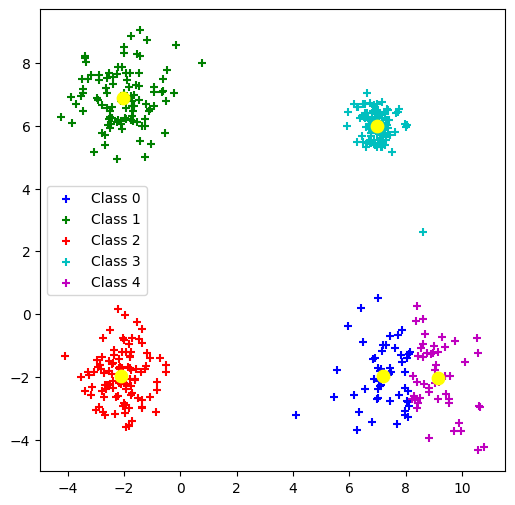

In [8]:
m = 5 # số cụm khởi tạo
kmeans = KMeans(n_clusters=m, random_state=random_state) # thuật toán kmean
kmeans.fit(X1); # huấn luyện tìm m cluster

cluster_centers = kmeans.cluster_centers_
cluster_inertia = kmeans.inertia_

# kiểm tra số mẫu phân lớp đúng
y_pred          = kmeans.labels_
correct_labels = sum(y1 == y_pred)

print(f'Centers:\n{cluster_centers}')
print(f'Inertia: {cluster_inertia}')
print(f'Correct Labels: {correct_labels} / {len(df_points)}')
print('Accuracy score: {0:0.2f}'. format(correct_labels/float(len(df_points))))

print()
print(f'Predict: {y_pred[0:20]} ...')
# vẽ tập dữ liệu điểm dự đoán
plt.figure(figsize=(6,6))     # độ lớn của khung vẽ
for i in range(m):
    # Điểm trung tâm của lớp
    print(f'Center {i}: {cluster_centers[i]}')

    # vẽ tập điểm
    plt.scatter(X1[y_pred==i, 0], X1[y_pred==i, 1], marker='+',
                c = colors[i], label = f"Class {i}")
    # vẽ tâm
    plt.scatter(cluster_centers[i, 0], cluster_centers[i, 1], marker='o',
                c='yellow', s = 80)
    pass # for
plt.legend()
plt.show()

#### 2.4. Số cụm m = 4 xác định trước

Tập $m=4$ cụm xác định trước lần lượt là $\theta_1 = \left(1, 1\right)$ (cũ: $\left(-2, -2\right)$), $\theta_2 = \left(1.1, 1.1\right)$ (cũ: $\left(-2.1, -2.1\right)$), $\theta_3 = \left(1.0, 1.2\right)$ (cũ: $\left(-2.0, -2.2\right)$), $\theta_4 = \left(1.1, 1.2\right)$ (cũ: $\left(-2.1, -2.2\right)$)

Centers:
[[-2.0924514  -1.97278214]
 [ 8.14921    -1.99398747]
 [-2.04053365  6.88635459]
 [ 6.98573044  6.00395933]]
Inertia: 573.1019378503071
Correct Labels: 399 / 400
Accuracy score: 1.00

Predict: [2 2 3 3 3 3 2 1 0 0 2 0 3 0 0 0 2 1 0 1] ...
Center 0: [-2.0924514  -1.97278214]
Center 1: [ 8.14921    -1.99398747]
Center 2: [-2.04053365  6.88635459]
Center 3: [6.98573044 6.00395933]


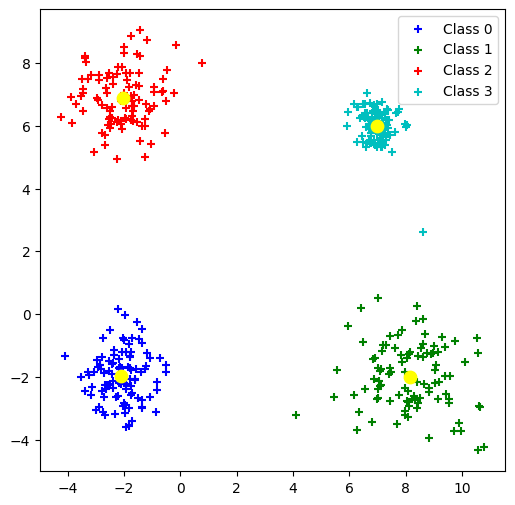

In [9]:
m = 4 # số cụm khởi tạo
kmeans = KMeans(n_clusters=m,
                init = np.array([[1,1], [1.1, 1.1], [1.0, 1.2], [1.1,1.2]]), # (cũ: [[-2,-2], [-2.1, -2.1], [-2.0, -2.2], [-2.1,-2.2]])
                n_init = 1, # chỉ chạy 1 lần k_means
                random_state=random_state) # thuật toán kmean
kmeans.fit(X1); # huấn luyện tìm m cluster

cluster_centers = kmeans.cluster_centers_
cluster_inertia = kmeans.inertia_

# kiểm tra số mẫu phân lớp đúng
y_pred          = kmeans.labels_
correct_labels = sum(y1 == y_pred)

print(f'Centers:\n{cluster_centers}')
print(f'Inertia: {cluster_inertia}')
print(f'Correct Labels: {correct_labels} / {len(df_points)}')
print('Accuracy score: {0:0.2f}'. format(correct_labels/float(len(df_points))))

print()
print(f'Predict: {y_pred[0:20]} ...')
# vẽ tập dữ liệu điểm dự đoán
plt.figure(figsize=(6,6))     # độ lớn của khung vẽ
for i in range(m):
    # Điểm trung tâm của lớp
    print(f'Center {i}: {cluster_centers[i]}')

    # vẽ tập điểm
    plt.scatter(X1[y_pred==i, 0], X1[y_pred==i, 1], marker='+',
                c = colors[i], label = f"Class {i}")
    # vẽ tâm
    plt.scatter(cluster_centers[i, 0], cluster_centers[i, 1], marker='o',
                c='yellow', s = 80)
    pass # for
plt.legend()
plt.show()

### 3. Tìm số lượng cụm tối ưu bởi điểm cong (elbow method)

+ Chúng ta thực hiện k-means nhiều lần với k=2, 3, ...
+ Vẽ đồ thị độ đo khoảng cách giữa các phần tử trong cụm
+ Tìm điểm cong quan trọng của đồ thị

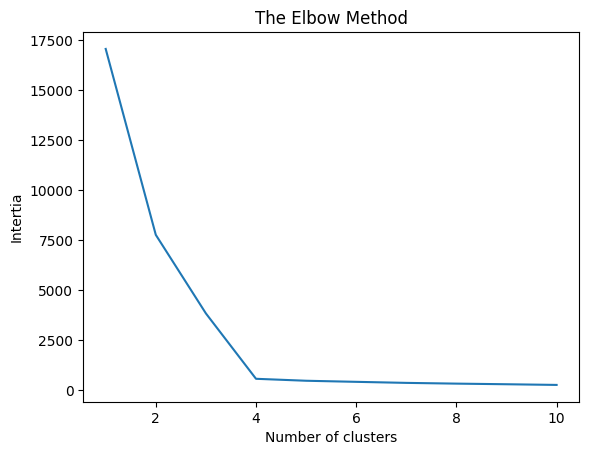

In [10]:
list_intertia = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters = i,      # số cluster
                    init = 'k-means++',  # khởi tạo ngẫu nhiên dùng k-means++
                    max_iter = 300,      # số lần lặp trong thuật toán
                    n_init = 10,         # số lần chạy lại k-means và lấy tốt nhất
                    random_state = random_state,
                   )
    kmeans.fit(X1)
    list_intertia.append(kmeans.inertia_)
plt.plot(range(1, 11), list_intertia)
plt.title('The Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('Intertia')
plt.show()

+ Hình trên cho thấy số lượng cluster tối ưu là 4

## Bài 2. Bài tập áp dụng

Áp dụng thuật toán k-means cho tập dữ liệu sau:
+ Tập điểm dữ liệu $X_2$ gồm 400 điểm 2 chiều chứa 4 lớp với số lượng phần tử bằng nhau. Các tập hợp điểm trong lớp tuân theo phân phối Gaussian với means $m_0=\left(0, 0\right)$, $m_1=\left(4, 0\right)$, $m_2=\left(0, 4\right)$, và $m_3=\left(5, 4\right)$ với các covariance matrices tương ứng $S_0=I$, $S_1=1.5I$, $S_2=1.1I$, $S_3=0.5I$.

+ Tập điểm dữ liệu $X_3$ gồm 300 điểm 2 chiều chỉ có 1 lớp dữ liệu với mean $m_1=\left(0, 0\right)$ và $S_1 = I$.

### 1. Xử lý tập dữ liệu $X_2$

Tạo tập dữ liệu $X_2$ với các thông số: $m_0=(0,0), m_1=(4,0), m_2=(0,4), m_3=(5,4)$ và các độ lệch chuẩn tương ứng.

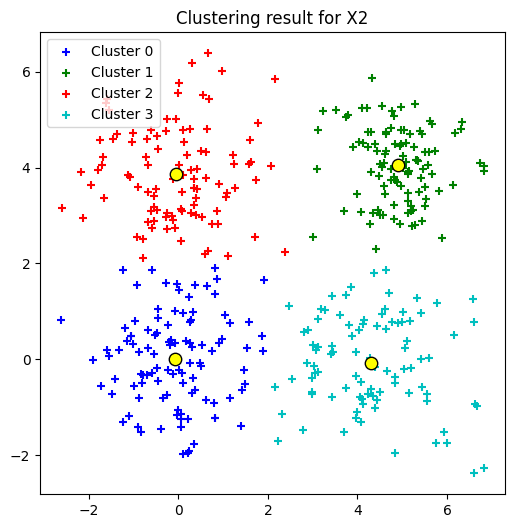

Inertia for X2: 698.681728361458


In [11]:
# 1. Khởi tạo dữ liệu X2
X2, y2 = make_blobs(n_samples=400,
                    centers=[[0,0], [4,0], [0,4], [5,4]],
                    cluster_std=[1.0, 1.22, 1.05, 0.71], # sqrt của 1, 1.5, 1.1, 0.5
                    random_state=random_state)

# 2. Áp dụng K-means với m=4
kmeans_x2 = KMeans(n_clusters=4, random_state=random_state)
kmeans_x2.fit(X2)
y_pred_x2 = kmeans_x2.labels_
centers_x2 = kmeans_x2.cluster_centers_

# 3. Hiển thị kết quả
plt.figure(figsize=(6,6))
for i in range(4):
    plt.scatter(X2[y_pred_x2==i, 0], X2[y_pred_x2==i, 1], marker='+', c=colors[i], label=f'Cluster {i}')
    plt.scatter(centers_x2[i,0], centers_x2[i,1], marker='o', c='yellow', s=80, edgecolors='black')

plt.title("Clustering result for X2")
plt.legend()
plt.show()

print(f"Inertia for X2: {kmeans_x2.inertia_}")

### 2. Xử lý tập dữ liệu $X_3$

Tập dữ liệu $X_3$ chỉ gồm 1 lớp (300 điểm) tại gốc tọa độ.

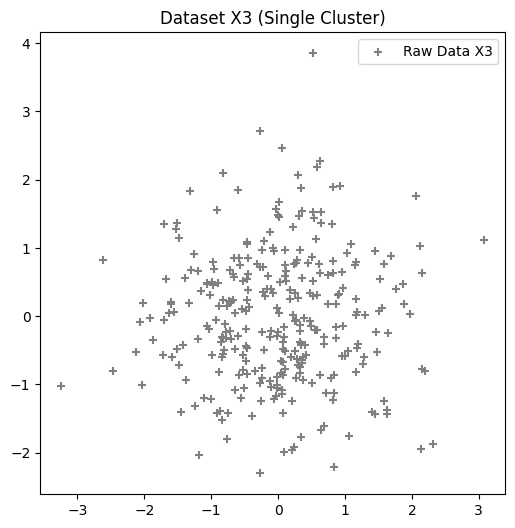

In [12]:
# 1. Khởi tạo dữ liệu X3
X3, y3 = make_blobs(n_samples=300,
                    centers=[[0,0]],
                    cluster_std=[1.0],
                    random_state=random_state)

# 2. Hiển thị dữ liệu gốc X3
plt.figure(figsize=(6,6))
plt.scatter(X3[:, 0], X3[:, 1], marker='+', c='gray', label='Raw Data X3')
plt.title("Dataset X3 (Single Cluster)")
plt.legend()
plt.show()

### 3. Tìm số cụm tối ưu cho $X_2$ bằng Elbow Method

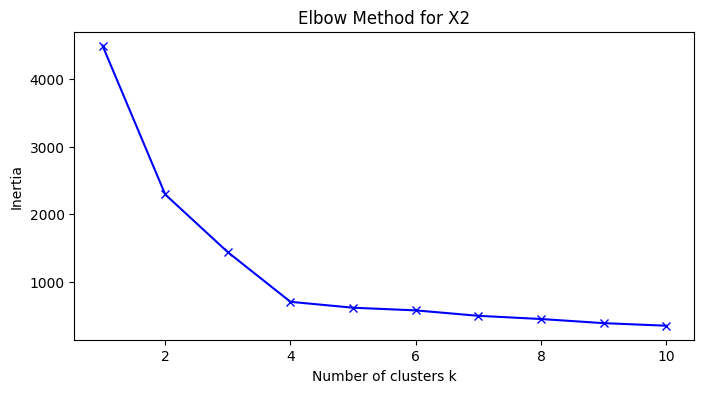

In [13]:
inertia_x2 = []
K_range = range(1, 11)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=random_state)
    km.fit(X2)
    inertia_x2.append(km.inertia_)

plt.figure(figsize=(8,4))
plt.plot(K_range, inertia_x2, 'bx-')
plt.xlabel('Number of clusters k')
plt.ylabel('Inertia')
plt.title('Elbow Method for X2')
plt.show()

# Kết thúc